# Solving FrozenLake with Policy Iteration

In [1]:
!pip install -q "gymnasium[toy-text]"

In [2]:
from typing import Any, cast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium.envs.toy_text.frozen_lake import FrozenLakeEnv

## 1. Load the FrozenLake-v1 environment

In [3]:
env = gym.make(
  'FrozenLake-v1',
  desc=None,
  map_name='4x4',
  is_slippery=True,
  render_mode='rgb_array',
)
lake = cast(FrozenLakeEnv, env.unwrapped)
state, info = env.reset(seed=42)

print('States:', env.observation_space)
print('Actions:', env.action_space)
print(lake.desc.astype(str))

States: Discrete(16)
Actions: Discrete(4)
[['S' 'F' 'F' 'F']
 ['F' 'H' 'F' 'H']
 ['F' 'F' 'F' 'H']
 ['H' 'F' 'F' 'G']]


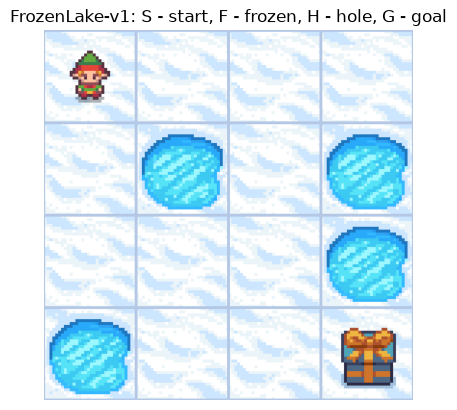

In [5]:
plt.imshow(cast(np.ndarray, env.render()))
plt.axis('off')
plt.title('FrozenLake-v1: S - start, F - frozen, H - hole, G - goal')
plt.show()

In [7]:
ACTIONS = ['LEFT', 'DOWN', 'RIGHT', 'UP']
transitions: dict[int, dict[int, list[tuple[float, int, float, bool]]]] = lake.P

for action, name in enumerate(ACTIONS):
  print(f'state 0, {name}:', transitions[0][action])

state 0, LEFT: [(0.33333333333333337, 0, 0, False), (0.3333333333333333, 0, 0, False), (0.33333333333333337, 4, 0, False)]
state 0, DOWN: [(0.33333333333333337, 0, 0, False), (0.3333333333333333, 4, 0, False), (0.33333333333333337, 1, 0, False)]
state 0, RIGHT: [(0.33333333333333337, 4, 0, False), (0.3333333333333333, 1, 0, False), (0.33333333333333337, 0, 0, False)]
state 0, UP: [(0.33333333333333337, 1, 0, False), (0.3333333333333333, 0, 0, False), (0.33333333333333337, 0, 0, False)]


## 2. Policy evaluation: compute_value_function()

In [11]:
def compute_value_function(
  policy: np.ndarray,
  transitions: dict[int, dict[int, list[tuple[float, int, float, bool]]]],
  gamma: float = 1.0,
  threshold: float = 1e-10,
) -> np.ndarray:
  n_states = len(transitions)
  value_table = np.zeros(n_states)

  while True:
    updated_value_table = np.copy(value_table)
    for state in range(n_states):
      action = int(policy[state])
      value_table[state] = sum(
        trans_prob * (reward + gamma * updated_value_table[next_state])
        for trans_prob, next_state, reward, _ in transitions[state][action]
      )
    if np.sum(np.fabs(updated_value_table - value_table)) <= threshold:
      break

  return value_table

In [13]:
def extract_policy(
  value_table: np.ndarray,
  transitions: dict[int, dict[int, list[tuple[float, int, float, bool]]]],
  gamma: float = 1.0,
) -> np.ndarray:
  n_states = len(transitions)
  n_actions = len(transitions[0])
  policy = np.zeros(n_states, dtype=int)

  for state in range(n_states):
    q_table = np.zeros(n_actions)
    for action in range(n_actions):
      for trans_prob, next_state, reward, _ in transitions[state][action]:
        q_table[action] += trans_prob * (reward + gamma * value_table[next_state])
    policy[state] = np.argmax(q_table)

  return policy

## 3. policy_iteration()

In [16]:
def policy_iteration(
  env: Any,
  gamma: float = 1.0,
  max_iterations: int = 200_000,
  verbose: bool = True,
) -> tuple[np.ndarray, np.ndarray, int]:
  transitions = env.unwrapped.P
  policy = np.zeros(env.observation_space.n, dtype=int)
  value_table = np.zeros(env.observation_space.n)

  for i in range(max_iterations):
    value_table = compute_value_function(policy, transitions, gamma)
    new_policy = extract_policy(value_table, transitions, gamma)
    if np.all(policy == new_policy):
      if verbose:
        print(f'Policy iteration converged at step {i + 1}.')
      return new_policy, value_table, i + 1
    policy = new_policy

  return policy, value_table, max_iterations

In [18]:
optimal_policy, optimal_values, n_iterations = policy_iteration(env, gamma=1.0)

print('Optimal policy:')
print(np.array(ACTIONS)[optimal_policy].reshape(4, 4))

Policy iteration converged at step 7.
Optimal policy:
[['LEFT' 'UP' 'UP' 'UP']
 ['LEFT' 'LEFT' 'LEFT' 'LEFT']
 ['UP' 'DOWN' 'LEFT' 'LEFT']
 ['LEFT' 'RIGHT' 'DOWN' 'LEFT']]


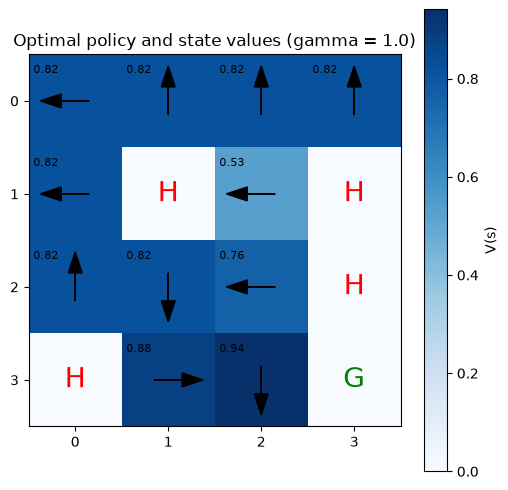

In [24]:
def plot_policy(env: Any, policy: np.ndarray, values: np.ndarray, title: str) -> None:
  desc = env.unwrapped.desc.astype(str)
  n_rows, n_cols = desc.shape
  arrows = {0: (-0.3, 0), 1: (0, 0.3), 2: (0.3, 0), 3: (0, -0.3)}

  fig, ax = plt.subplots(figsize=(6, 6))
  image = ax.imshow(values.reshape(n_rows, n_cols), cmap='Blues')
  fig.colorbar(image, ax=ax, label='V(s)')

  for state in range(n_rows * n_cols):
    row, col = divmod(state, n_cols)
    cell = desc[row, col]
    if cell in 'HG':
      ax.text(col, row, cell, ha='center', va='center', fontsize=20, color='red' if cell == 'H' else 'green')
      continue
    dx, dy = arrows[int(policy[state])]
    ax.arrow(col - dx / 2, row - dy / 2, dx, dy, head_width=0.15, color='black')
    ax.text(col - 0.45, row - 0.3, f'{values[state]:.2f}', ha='left', fontsize=8)

  ax.set_xticks(range(n_cols))
  ax.set_yticks(range(n_rows))
  ax.set_title(title)
  plt.show()


plot_policy(env, optimal_policy, optimal_values, 'Optimal policy and state values (gamma = 1.0)')

## 4. Visualize the optimal policy with show_render()

start


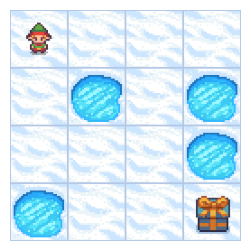

step 1: LEFT -> state 0


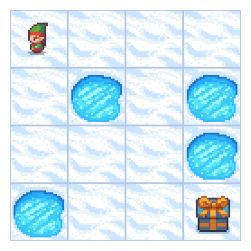

step 2: LEFT -> state 4


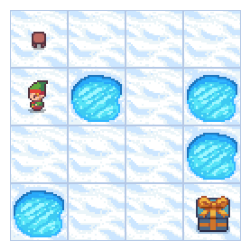

step 3: LEFT -> state 8


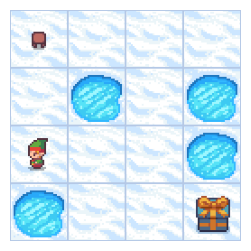

step 4: UP -> state 9


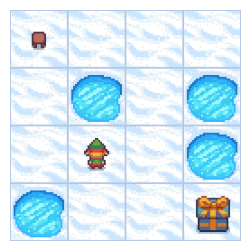

step 5: DOWN -> state 10


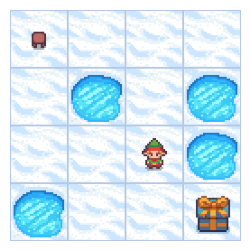

step 6: LEFT -> state 14


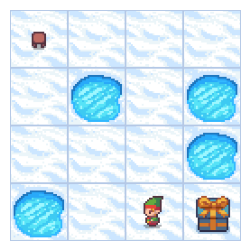

step 7: DOWN -> state 15


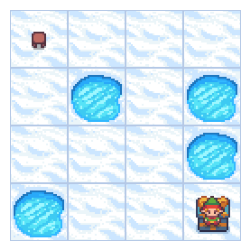

Reached the goal!


In [31]:
def show_render(img: np.ndarray) -> None:
  plt.figure(figsize=(3, 3))
  plt.imshow(img)
  plt.axis('off')
  plt.show()


def play_policy(env: Any, policy: np.ndarray, seed: int = 42, max_steps: int = 100) -> None:
  state, _ = env.reset(seed=seed)
  print('start')
  show_render(env.render())

  for step in range(max_steps):
    action = int(policy[state])
    state, reward, terminated, truncated, _ = env.step(action)
    print(f'step {step + 1}: {ACTIONS[action]} -> state {state}')
    show_render(env.render())
    if terminated or truncated:
      print('Reached the goal!' if reward > 0 else 'Fell into a hole.')
      break


play_policy(env, optimal_policy, seed=42)

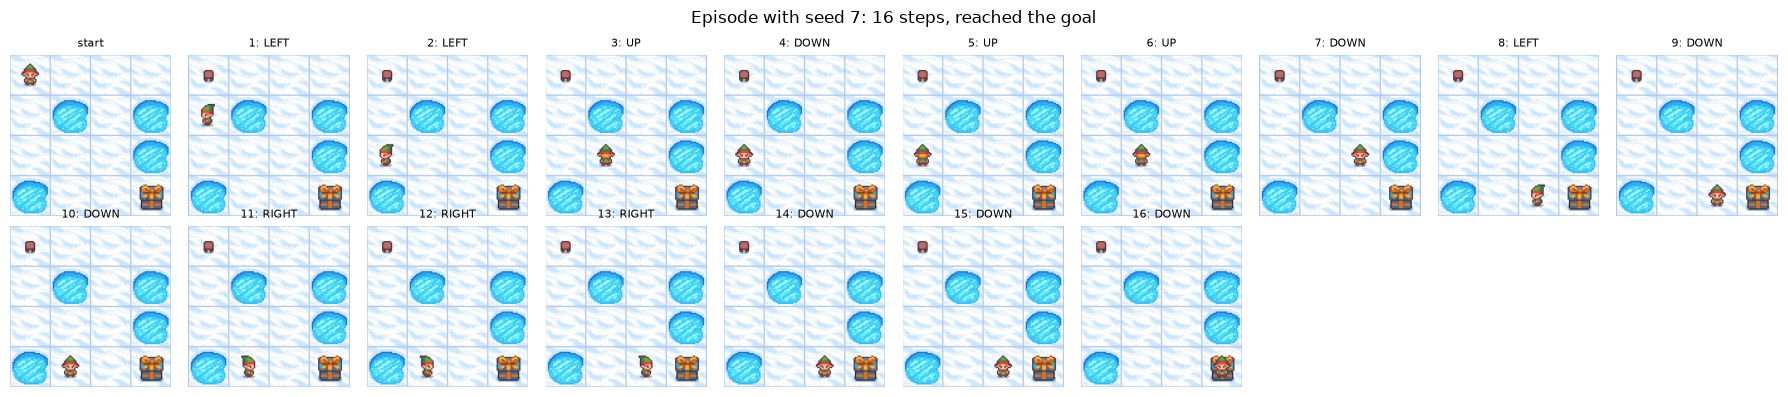

In [34]:
def show_episode(env: Any, policy: np.ndarray, seed: int = 42, max_steps: int = 100, n_cols: int = 10) -> None:
  state, _ = env.reset(seed=seed)
  frames = [env.render()]
  titles = ['start']
  total_reward = 0.0

  for step in range(max_steps):
    action = int(policy[state])
    state, reward, terminated, truncated, _ = env.step(action)
    total_reward += float(reward)
    frames.append(env.render())
    titles.append(f'{step + 1}: {ACTIONS[action]}')
    if terminated or truncated:
      break

  n_rows = int(np.ceil(len(frames) / n_cols))
  fig, axes = plt.subplots(n_rows, n_cols, figsize=(1.8 * n_cols, 2.0 * n_rows))
  for ax in np.ravel(axes):
    ax.axis('off')
  for ax, frame, title in zip(np.ravel(axes), frames, titles):
    ax.imshow(frame)
    ax.set_title(title, fontsize=8)

  result = 'reached the goal' if total_reward > 0 else 'fell into a hole'
  fig.suptitle(f'Episode with seed {seed}: {len(frames) - 1} steps, {result}')
  plt.tight_layout()
  plt.show()


show_episode(env, optimal_policy, seed=7)

## 5. Evaluate the policy

In [38]:
def evaluate_policy(env: Any, policy: np.ndarray, n_episodes: int = 1000, max_steps: int = 200) -> tuple[float, float]:
  wins = 0
  steps_to_goal = []

  for episode in range(n_episodes):
    state, _ = env.reset(seed=episode)
    for step in range(max_steps):
      state, reward, terminated, truncated, _ = env.step(int(policy[state]))
      if terminated or truncated:
        if reward > 0:
          wins += 1
          steps_to_goal.append(step + 1)
        break

  return wins / n_episodes, float(np.mean(steps_to_goal)) if steps_to_goal else float('nan')


rng = np.random.default_rng(42)
random_policy = rng.integers(0, len(ACTIONS), len(transitions))

optimal_success, optimal_steps = evaluate_policy(env, optimal_policy)
random_success, random_steps = evaluate_policy(env, random_policy)

pd.DataFrame({
  'success rate': [optimal_success, random_success],
  'mean steps to goal': [optimal_steps, random_steps],
}, index=['optimal policy', 'random policy'])

,success rate,mean steps to goal
optimal policy,0.755,38.364238
random policy,0.000,NaN


## 6. Experiments with the discount factor and slippery ice

In [50]:
experiment_rows = []
experiment_policies = {}

for is_slippery in [True, False]:
  experiment_env = gym.make('FrozenLake-v1', is_slippery=is_slippery)
  for gamma in [0.5, 0.9, 0.99, 1.0]:
    policy, values, iterations = policy_iteration(experiment_env, gamma=gamma, max_iterations=1000, verbose=False)
    success, steps = evaluate_policy(experiment_env, policy)
    experiment_policies[(is_slippery, gamma)] = (policy, values)
    experiment_rows.append({
      'slippery': is_slippery,
      'gamma': gamma,
      'iterations': iterations,
      'V(start)': values[0],
      'success rate': success,
      'mean steps to goal': steps,
    })

experiments = pd.DataFrame(experiment_rows)
experiments.round(3)

,slippery,gamma,iterations,V(start),success rate,mean steps to goal
0,True,0.50,5,0.000,0.432,28.683
1,True,0.90,6,0.069,0.741,36.630
2,True,0.99,7,0.542,0.755,38.364
3,True,1.00,7,0.824,0.755,38.364
4,False,0.50,7,0.031,1.000,6.000
5,False,0.90,7,0.590,1.000,6.000
6,False,0.99,7,0.951,1.000,6.000
7,False,1.00,1000,0.000,0.000,NaN


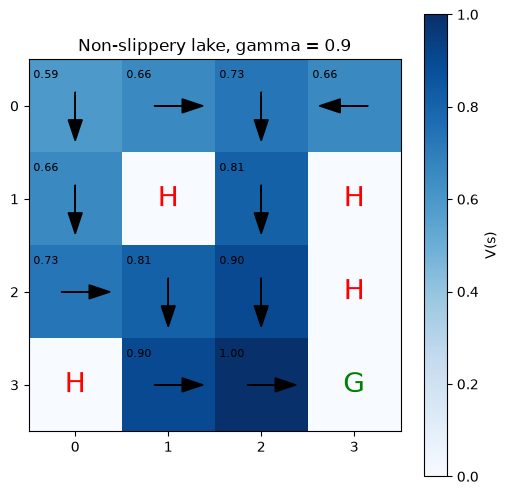

start


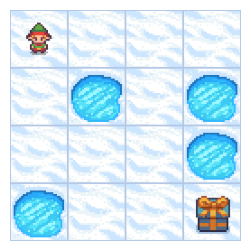

step 1: DOWN -> state 4


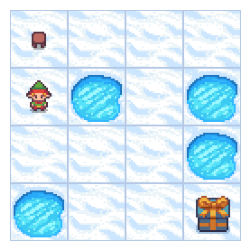

step 2: DOWN -> state 8


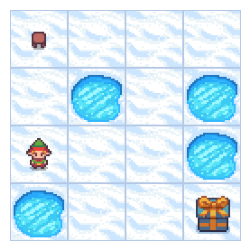

step 3: RIGHT -> state 9


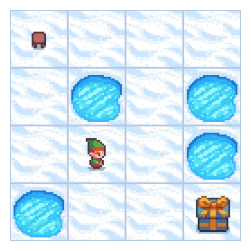

step 4: DOWN -> state 13


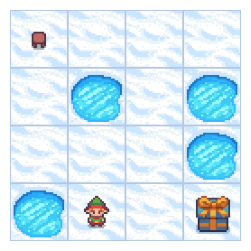

step 5: RIGHT -> state 14


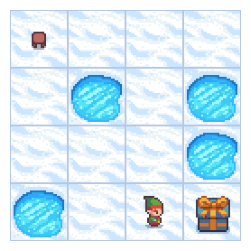

step 6: RIGHT -> state 15


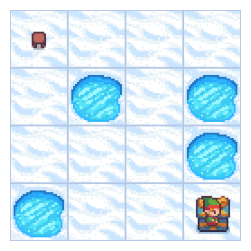

Reached the goal!


In [55]:
deterministic_env = gym.make('FrozenLake-v1', is_slippery=False, render_mode='rgb_array')
deterministic_policy, deterministic_values = experiment_policies[(False, 0.9)]

plot_policy(deterministic_env, deterministic_policy, deterministic_values, 'Non-slippery lake, gamma = 0.9')
play_policy(deterministic_env, deterministic_policy)

Policy iteration converged at step 11.
8x8 map: success rate = 0.631, mean steps to goal = 62.5


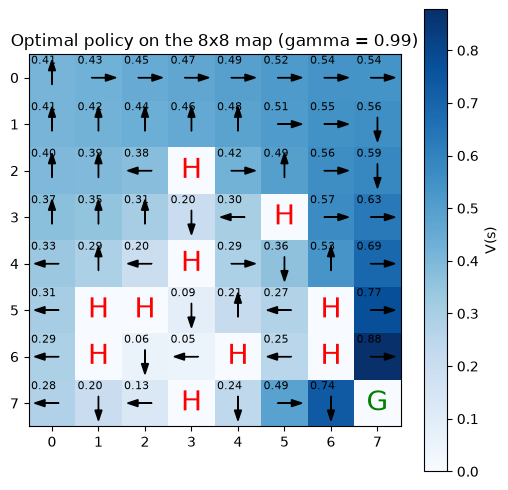

In [59]:
large_env = gym.make('FrozenLake-v1', map_name='8x8', render_mode='rgb_array')
large_policy, large_values, large_iterations = policy_iteration(large_env, gamma=0.99)
large_success, large_steps = evaluate_policy(large_env, large_policy)

print(f'8x8 map: success rate = {large_success:.3f}, mean steps to goal = {large_steps:.1f}')
plot_policy(large_env, large_policy, large_values, 'Optimal policy on the 8x8 map (gamma = 0.99)')

## Conclusion

- FrozenLake-v1 is a Markov decision process with 16 states and 4 actions; its transition model env.P gives, for every state and action, the next states with their probabilities and rewards, so the problem can be solved exactly by dynamic programming.
- compute_value_function() evaluates a fixed policy by iterating the Bellman expectation equation, extract_policy() makes it greedy with respect to those values, and policy_iteration() alternates the two until the policy stops changing.
- On the default slippery 4x4 map policy iteration converges in 7 steps; the optimal policy has V(start) = 0.82 and reaches the goal in 75.5% of 1000 test episodes (a random policy: 0%).
- show_render() replays the policy frame by frame: in the seed-42 episode the agent reaches the goal in 7 steps, in the seed-7 episode it needs 16 steps because slips keep pushing it sideways and it has to repeat moves from safe cells.
- The optimal policy looks counter-intuitive (LEFT at the start, UP along the top row): on slippery ice the agent chooses moves whose sideways slips can never drop it into a hole, even if this makes the path longer (38 steps on average).
- The discount factor matters: with gamma = 0.5 future reward is almost worthless and success drops to 43%; gamma = 0.99 and 1.0 give the best policy (75.5%).
- On the non-slippery lake any gamma < 1 gives the shortest 6-step path with 100% success. With gamma = 1 policy iteration never converges: standing next to the goal is valued the same as entering it, so the algorithm keeps switching between two equally-scored policies.
- On the larger 8x8 slippery map policy iteration converges in 11 steps and the policy succeeds in 63% of episodes, so the method scales well while the MDP model is known.